# QeSA

Here we introduce you to Quantum-enhanced Simulated Annealing (QeSA)

The basic idea of the approach is to use the [QeMCMC](https://www.nature.com/articles/s41586-023-06095-4) subroutine within simulated annealing. The details can be found in our paper: [Methods for non-variational heuristic quantum optimisation
](https://arxiv.org/abs/2602.01353)


## Imports

In [1]:
from joblib import Parallel, delayed
from matplotlib import pyplot as plt

# This helps you build an example Ising model
from qemcmc.model import ModelMaker

# Internal imports from QeMCMC package
# sampler contains the classical and quantum enhanced MCMC sampler
from qemcmc.sampler import ClassicalProposal, AdiabaticProposal, QuenchProposal
from qemcmc.sampler.runners import MCMCRunner

# These are object useful to store the results of the MCMC simulation
from qemcmc.utils import plot_chains

import numpy as np
from tqdm import tqdm
from qesa.qesa import QeSA
import time


## Define model problem and algorithm parameters

In [14]:

# Define parameters
n = 8 # Number of spins in the system
reps = c_reps = 5 # How many markov chains to produce

steps = n_hops = 150 # Length of each markov chain

high_temp = 10.0
low_temp = 0.01
temps = np.logspace(np.log10(high_temp), np.log10(low_temp) , steps)
model = ModelMaker(n, "Fully Connected Ising", "test").model

model_lowest = model.lowest_energy



In [15]:
def run_single_repetition(model, proposal, n_hops, temps):
    """Worker function to handle a single simulation run."""
    sa = QeSA(model, proposal=proposal)
    chain = sa.run_simulated_annealing(n_hops=n_hops, temp_scaling=temps)
    
    return chain

In [16]:
g = (0.3,0.5)
t = (1,10)
qeproposal = QuenchProposal(model, g, t)
q_chains = []
for _ in tqdm(range(reps)):
    q_chains.append(run_single_repetition(model, qeproposal, n_hops, temps))




100%|██████████| 5/5 [00:14<00:00,  2.94s/it]


In [17]:
gamma = 3.0
alpha = 1.5
kappa = (0,3)
adiproposal = AdiabaticProposal(model, gamma, alpha, kappa, delta_t = 0.3)
adi_chains = []
for _ in tqdm(range(reps)):
    adi_chains.append(run_single_repetition(model, adiproposal, n_hops, temps))



100%|██████████| 5/5 [00:54<00:00, 10.93s/it]


In [19]:
cproposal = ClassicalProposal(model, method = "local")
c_chains = []
for _ in tqdm(range(reps)):
    c_chains.append(run_single_repetition(model, cproposal, n_hops, temps))

uniproposal = ClassicalProposal(model, method = "uniform")
uni_chains = []
for _ in tqdm(range(reps)):
    uni_chains.append(run_single_repetition(model, uniproposal, n_hops, temps))



100%|██████████| 5/5 [00:00<00:00, 150.73it/s]


## Run classical MCMC

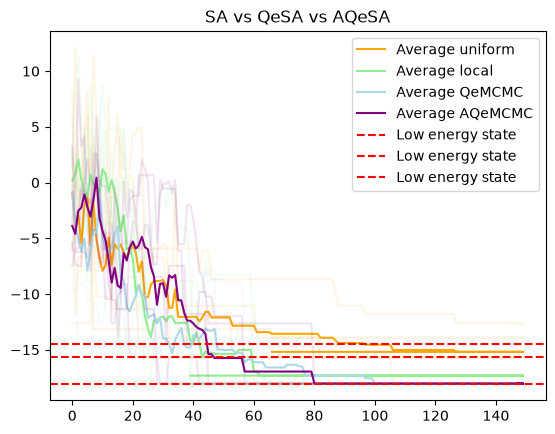

In [20]:

plot_chains(uni_chains, "orange", "uniform", plot_individual_chains=True)
plot_chains(c_chains, "lightgreen", "local", plot_individual_chains=True)
plot_chains(q_chains, "lightblue", "QeMCMC", plot_individual_chains=True)
plot_chains(adi_chains, "purple", "AQeMCMC", plot_individual_chains=True)
plt.title("SA vs QeSA vs AQeSA")

lowest_energies, degeneracies, lowest_configs = model.get_lowest_energies(3, return_configurations=True)
for i, energy in enumerate(lowest_energies):
    if i<3:
        plt.axhline(energy, color="red", linestyle="--", label=f"Low energy state")
plt.legend()
